<a href="https://colab.research.google.com/github/QueenWafa/grain-classification-cnn/blob/main/Grain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy
from tensorflow import keras
from keras.constraints import max_norm
from keras.utils import to_categorical
import matplotlib.pyplot as plt
from keras.models import Sequential, load_model
from keras.layers import Conv2D, MaxPool2D, Dense, Dropout, Flatten
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
print(os.listdir("/content/drive/MyDrive/Grains"))

['Rice', 'Barli']


In [4]:
!pip install pillow-heif
from PIL import Image
from pillow_heif import register_heif_opener
register_heif_opener()

from sklearn.model_selection import train_test_split
import numpy as np

data_dir = "/content/drive/MyDrive/Grains"
img_size = 32

classes = ["Barli", "Rice"]

X = []
y = []

for label, class_name in enumerate(classes):
    folder = os.path.join(data_dir, class_name)
    if not os.path.exists(folder):
        print(f"Warning: Directory not found: {folder}. Skipping.")
        continue
    for file_name in os.listdir(folder):
        img_path = os.path.join(folder, file_name)
        try:
            img = Image.open(img_path).convert("RGB").resize((img_size, img_size))
            X.append(np.array(img))
            y.append(label)
        except Exception as e:
            print(f"Error processing {img_path}: {e}")
            pass

X = np.array(X)
y = np.array(y)

print("Total images loaded:", X.shape[0])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 44.3 MB/s eta 0:00:00
Total images loaded: 1039
(831, 32, 32, 3) (831,) (208, 32, 32, 3) (208,)


In [5]:
y_train[0]

np.int64(0)

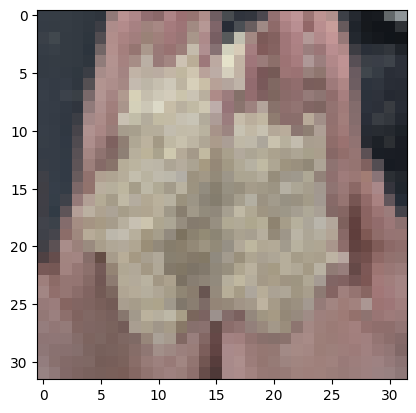

In [6]:
plt.imshow(X_train[0])

In [7]:
# --- STEP 3: ADVANCED EXPLORATORY DATA ANALYSIS (EDA) ---
print("\nStep 3: Performing Advanced EDA...")
num_barli = len(os.listdir(os.path.join(data_dir, "Barli")))
num_rice = len(os.listdir(os.path.join(data_dir, "Rice")))
print(f"--- Dataset Statistics ---")
print(f"Total Barli: {num_barli}")
print(f"Total Rice: {num_rice}")
print(f"Total Images: {num_barli + num_rice}")


Step 3: Performing Advanced EDA...
--- Dataset Statistics ---
Total Barli: 547
Total Rice: 492
Total Images: 1039


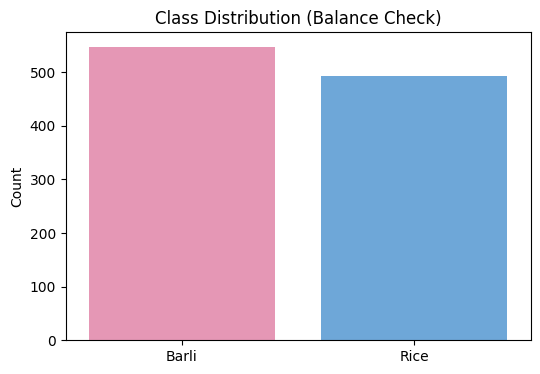

In [8]:
# 3.2 Plot Class Balance
import seaborn as sns
plt.figure(figsize=(6, 4))                       # New 6x4-inch figure
sns.barplot(x=['Barli', 'Rice'],                 # Two bars on the x-axis: Barli and Rice
            y=[num_barli, num_rice],             # Bar heights = the two counts
            hue=['Barli', 'Rice'],               # Colour each bar by its label
            palette=['#F28AB2', '#5DA9E9'],      # Blue for Barli, red for Rice
            legend=False)                        # No legend (labels already on the x-axis)
plt.title('Class Distribution (Balance Check)')  # Chart title
plt.ylabel('Count')                              # Y-axis label
plt.show()                                       # Display the chart


Step 3.3: Analyzing image dimensions...
Number of images checked: 1039
Width  - min: 436, max: 4032, average: 3524
Height - min: 263, max: 4032, average: 2753


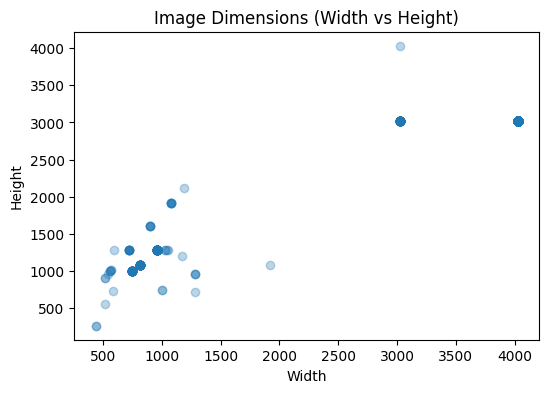

In [9]:
# 3.3 Image Dimension Analysis
print("\nStep 3.3: Analyzing image dimensions...")

widths = []
heights = []

for class_name in ["Barli", "Rice"]:
    folder = os.path.join(data_dir, class_name)
    for file_name in os.listdir(folder):
        img_path = os.path.join(folder, file_name)
        try:
            img = Image.open(img_path)
            w, h = img.size
            widths.append(w)
            heights.append(h)
        except Exception as e:
            print(f"Error reading {img_path}: {e}")
            pass

print(f"Number of images checked: {len(widths)}")
print(f"Width  - min: {min(widths)}, max: {max(widths)}, average: {sum(widths)/len(widths):.0f}")
print(f"Height - min: {min(heights)}, max: {max(heights)}, average: {sum(heights)/len(heights):.0f}")

plt.figure(figsize=(6,4))
plt.scatter(widths, heights, alpha=0.3)
plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Image Dimensions (Width vs Height)")
plt.show()

In [10]:
# --- Check for duplicate images in Rice folder (and Barli too) ---
import hashlib

def get_image_hash(img_path):
    with open(img_path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

for class_name in ["Barli", "Rice"]:
    folder = os.path.join(data_dir, class_name)
    hashes = {}
    duplicates = []
    for file_name in os.listdir(folder):
        img_path = os.path.join(folder, file_name)
        try:
            h = get_image_hash(img_path)
            if h in hashes:
                duplicates.append((file_name, hashes[h]))
            else:
                hashes[h] = file_name
        except Exception as e:
            print(f"Error hashing {img_path}: {e}")

    print(f"{class_name}: {len(duplicates)} duplicate file(s) found")
    for dup, original in duplicates:
        print(f"  '{dup}' is a duplicate of '{original}'")

Barli: 0 duplicate file(s) found
Rice: 141 duplicate file(s) found
  'c6459c30-a288-44c3-ae85-93ca70b441b3.jpg' is a duplicate of '2d2ffe07-8819-4d1b-81b1-d98c57a0733a.jpg'
  'IMG_6746.JPG' is a duplicate of 'IMG_6766.JPG'
  'IMG_6762.JPG' is a duplicate of 'IMG_6782.JPG'
  'IMG_6747.JPG' is a duplicate of 'IMG_6767.JPG'
  'IMG_6751.JPG' is a duplicate of 'IMG_6771.JPG'
  'IMG_6748.JPG' is a duplicate of 'IMG_6768.JPG'
  'IMG_6757.JPG' is a duplicate of 'IMG_6777.JPG'
  'IMG_6750.JPG' is a duplicate of 'IMG_6770.JPG'
  'IMG_6760.JPG' is a duplicate of 'IMG_6780.JPG'
  'IMG_6749.JPG' is a duplicate of 'IMG_6769.JPG'
  'IMG_2026_07_09-14_08_50_5360_581E321F.JPEG' is a duplicate of 'IMG_2026_07_09-14_08_50_5360_581E321F (1).JPEG'
  'IMG_2026_07_09-14_08_42_3490_C4807CF4.JPEG' is a duplicate of 'IMG_2026_07_09-14_08_42_3490_C4807CF4 (1).JPEG'
  'IMG_2026_07_09-14_08_47_0930_25445CAB.JPEG' is a duplicate of 'IMG_2026_07_09-14_08_47_0930_25445CAB (1).JPEG'
  'IMG_2026_07_09-14_08_45_9880_FA8

In [11]:
import shutil

source_dir = "/content/drive/MyDrive/Grains"
edited_dir = "/content/drive/MyDrive/Grains_Edited"

if os.path.exists(edited_dir):
    print("Grains_Edited already exists — skipping copy to avoid overwriting.")
else:
    shutil.copytree(source_dir, edited_dir)
    print(f"Copied entire folder from {source_dir} to {edited_dir}")

print("Barli files in edited folder:", len(os.listdir(os.path.join(edited_dir, "Barli"))))
print("Rice files in edited folder:", len(os.listdir(os.path.join(edited_dir, "Rice"))))

Grains_Edited already exists — skipping copy to avoid overwriting.
Barli files in edited folder: 547
Rice files in edited folder: 492


In [12]:
# --- Delete duplicate files in Rice folder (Grains_Edited copy only) ---
edited_dir = "/content/drive/MyDrive/Grains_Edited"
folder = os.path.join(edited_dir, "Rice")

deleted_count = 0
for d, original in duplicates:
    file_path = os.path.join(folder, d)
    try:
        os.remove(file_path)
        deleted_count += 1
        print(f"Deleted: {d}")
    except Exception as e:
        print(f"Could not delete {d}: {e}")

print(f"\nTotal deleted: {deleted_count}")
print(f"Remaining files in Rice folder: {len(os.listdir(folder))}")

Deleted: c6459c30-a288-44c3-ae85-93ca70b441b3.jpg
Deleted: IMG_6746.JPG
Deleted: IMG_6762.JPG
Deleted: IMG_6747.JPG
Deleted: IMG_6751.JPG
Deleted: IMG_6748.JPG
Deleted: IMG_6757.JPG
Deleted: IMG_6750.JPG
Deleted: IMG_6760.JPG
Deleted: IMG_6749.JPG
Deleted: IMG_2026_07_09-14_08_50_5360_581E321F.JPEG
Deleted: IMG_2026_07_09-14_08_42_3490_C4807CF4.JPEG
Deleted: IMG_2026_07_09-14_08_47_0930_25445CAB.JPEG
Deleted: IMG_2026_07_09-14_08_45_9880_FA87D437.JPEG
Deleted: IMG_2026_07_09-14_08_49_4100_DAD99F45.JPEG
Deleted: IMG_2026_07_09-14_08_44_8620_494B7B36.JPEG
Deleted: IMG_2026_07_09-14_08_48_2570_2C25966E.JPEG
Deleted: IMG_2026_07_09-14_08_52_8190_49FE8A14.JPEG
Deleted: IMG_2026_07_09-14_08_51_6770_EB92E708.JPEG
Deleted: IMG_2026_07_09-14_08_43_7760_6DDAE69E.JPEG
Deleted: IMG_2026_07_09-14_08_54_8060_4613F555.JPEG
Deleted: IMG_2026_07_09-14_08_54_1180_ADC84593.JPEG
Deleted: IMG_2026_07_09-14_08_55_9960_C386B6BF.JPEG
Deleted: IMG_2026_07_09-14_08_58_3420_B6801D43.JPEG
Deleted: IMG_2026_07_09-

In [13]:
# Point data_dir to the cleaned working folder
data_dir = "/content/drive/MyDrive/Grains_Edited"
print("Barli:", len(os.listdir(os.path.join(data_dir, "Barli"))))
print("Rice:", len(os.listdir(os.path.join(data_dir, "Rice"))))

Barli: 547
Rice: 351


In [14]:
# --- STEP 3.4: AUGMENT MINORITY CLASS (Rice) TO BALANCE DATASET ---
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("\nStep 3.4: Augmenting Rice images to balance the dataset...")

rice_indices = np.where(y == 1)[0]
X_rice = X[rice_indices]

num_barli_total = np.sum(y == 0)
num_rice_total = np.sum(y == 1)
num_needed = num_barli_total - num_rice_total

print(f"Barli: {num_barli_total}, Rice: {num_rice_total}, Need to generate: {num_needed}")

datagen = ImageDataGenerator(
    rotation_range=30,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.15,
    brightness_range=[0.8, 1.2]
)

augmented_images = []
augmented_labels = []

gen = datagen.flow(X_rice, batch_size=1)
count = 0
while count < num_needed:
    batch = next(gen)
    augmented_images.append(batch[0].astype("uint8"))
    augmented_labels.append(1)
    count += 1

augmented_images = np.array(augmented_images)
augmented_labels = np.array(augmented_labels)

X = np.concatenate([X, augmented_images], axis=0)
y = np.concatenate([y, augmented_labels], axis=0)

print(f"New total images: {X.shape[0]}")
print(f"New Barli count: {np.sum(y == 0)}, New Rice count: {np.sum(y == 1)}")


Step 3.4: Augmenting Rice images to balance the dataset...
Barli: 547, Rice: 492, Need to generate: 55
New total images: 1094
New Barli count: 547, New Rice count: 547


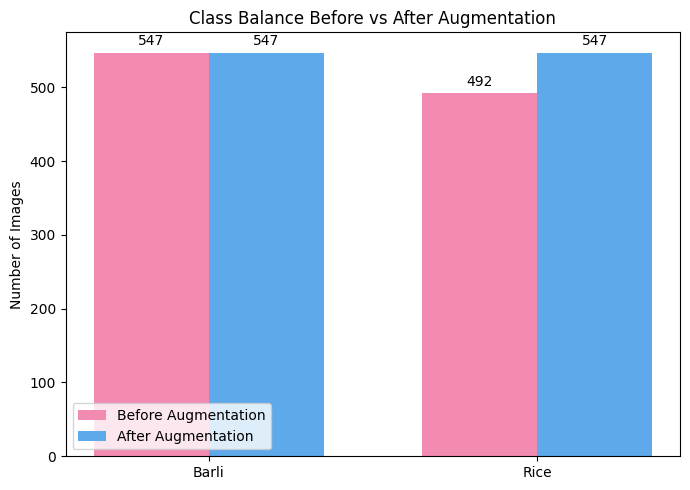

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Before and after counts
before_barli = 547
before_rice = 492
after_barli = np.sum(y == 0)
after_rice = np.sum(y == 1)

labels_chart = ["Barli", "Rice"]
before_counts = [before_barli, before_rice]
after_counts = [after_barli, after_rice]

x = np.arange(len(labels_chart))
width = 0.35

fig, ax = plt.subplots(figsize=(7,5))
bars1 = ax.bar(x - width/2, before_counts, width, label="Before Augmentation", color="#F28AB2")
bars2 = ax.bar(x + width/2, after_counts, width, label="After Augmentation", color="#5DA9E9")

ax.set_ylabel("Number of Images")
ax.set_title("Class Balance Before vs After Augmentation")
ax.set_xticks(x)
ax.set_xticklabels(labels_chart)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{int(height)}",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center", va="bottom")

plt.tight_layout()
plt.show()

## **Before Train**

In [17]:
# Normalize the input from 0-255 to between 0 and 1 by diviing by 255
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
X_train /= 255.0
X_test /= 255.0

In [18]:
# one-hot encode output yani Nural network bayad ye outpy araye 3 adadi biron bedeh oni ke dorost yek bashe, 0 ,1,0 (faghat format label avaz mikone)
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

In [19]:
#chon 2 class darim 2 elaman darim avali dorost vase hamin shod 1
y_train[0]

array([1., 0.])

In [20]:
num_classes = y_test.shape[1] #2


In [21]:
X_train.shape[1:]

(32, 32, 3)

# **Buliding CNN Model**  

In [22]:
#2 type : 1- creating layer by layer sequential 2- block by block and connect it together like lego
model = Sequential()


# **Feature Extraction** section ( estekhraj feature haye ax )



In [23]:
# padding= out and iput same
#* bayad avalin ovordi tarid konim ke che size ? bejaye input_shape=(32, 32, 3)) mitoni be paramet dige rabt bedim x_train.shape age begam az bo3ed dovom shoro kon[1:]
# be jaye adad halat parmetish mishe x_train.shape[1:]
#relu Rectified linear unit is active function -6->0 , 6-> same to remove not importanat value
model.add(Conv2D(32, (3, 3),padding='same' , input_shape=X_train.shape[1:], activation = 'relu'))
#2-7Layers , barye laye 2 input lazem nist


model.add(Conv2D(64, (3, 3),padding='same' ,  activation = 'relu'))
model.add(MaxPool2D())

model.add(Conv2D(64, (3, 3),padding='same' ,  activation = 'relu'))
model.add(MaxPool2D())

model.add(Conv2D(128, (3, 3),padding='same' ,  activation = 'relu'))
model.add(MaxPool2D())



/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
#alan ke chand layer Convelution and max pooling gozatim mitonim flatten konim yani az 2D be 1D
model.add(Flatten())


# **Classufaction** section ( ghesmati ke yad migire Dens layer ya neural network)

In [25]:
#bade faltten kardan nobat Dense layer yani hamon neural network shabke asabi, 32 tedad nerun
#laye badi mitone laye khoroji bashe ke tedad neron hash tedad kelashamo
model.add(Dense(32, activation = 'relu'))

model.add(Dense(num_classes, activation = 'softmax'))

# After creating Arcitucture of our model we need to complie it ( yani taze besazatesh)

In [26]:
#toie complie bayad barash ye chizi tarif koni maslan loss az che no3e bashe:
#loss chie ? vaghti khodesho trian mideh vaghti ye output khasi tashkhi mideh bayad ye meyari dashte bashe ke betone ba estefadeh az oon fuction tashkhis bedeh cheghadr khataa dare
#va biyad khodesh eslah kone , fucation mokhtalf sakhtan ta betone khata taskhis bede oni ke barye image classification bishtar az 2 class **categorical_crossentropy** vali barye man ke 2 class daram
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])#optimizer yani behbodzai Metrixs yani barye inke bebini amalkardet khobe ya badeh accurcy be training data bashe ye accurcy to validation bashe


In [27]:
model.summary()#over view shows Trainable params: 195,978 which is for deep learning small amount

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        65,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 195,810 (764.88 KB)

 Trainable params: 195,810 (764.88 KB)

 Non-trainable params: 0 (0.00 B)

# **Traning the model **

In [28]:
#fit kardan hamon train kardan # epochs : chand door tarmrinesh bedam3batch_size: chandta chanda bedeh trian beshan
history= model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=30, batch_size=64 )

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 491ms/step - accuracy: 0.5247 - loss: 0.6920 - val_accuracy: 0.5337 - val_loss: 0.6721
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 650ms/step - accuracy: 0.6245 - loss: 0.6590 - val_accuracy: 0.6346 - val_loss: 0.6211
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 432ms/step - accuracy: 0.6907 - loss: 0.5847 - val_accuracy: 0.7163 - val_loss: 0.5280
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 468ms/step - accuracy: 0.7425 - loss: 0.4817 - val_accuracy: 0.7308 - val_loss: 0.4689
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 525ms/step - accuracy: 0.7677 - loss: 0.4759 - val_accuracy: 0.8269 - val_loss: 0.4188
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 565ms/step - accuracy: 0.8135 - loss: 0.4031 - val_accuracy: 0.8606 - val_loss: 0.3828
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 483ms/step - accuracy: 0.8243 - loss: 0.3614 - val_accuracy: 0.8750 - val_loss: 0.2917
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 691ms/step - accuracy: 0.8568 - loss: 0.3603 - val_accuracy:

In [29]:
for key, value in history.history.items():
  print(key , value)

accuracy [0.5246690511703491, 0.6245487332344055, 0.6907340288162231, 0.7424789667129517, 0.7677497267723083, 0.8134777545928955, 0.8243080377578735, 0.8567990660667419, 0.8423585891723633, 0.8868832588195801, 0.8965102434158325, 0.9253910779953003, 0.9241877198219299, 0.9338147044181824, 0.94344162940979, 0.9494584798812866, 0.9699157476425171, 0.9795427322387695, 0.9819494485855103, 0.9843562245368958, 0.9831528067588806, 0.9951865077018738, 0.9975932836532593, 0.9987966418266296, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
loss [0.6920115351676941, 0.6590461730957031, 0.5846776366233826, 0.4817066490650177, 0.47590282559394836, 0.40307706594467163, 0.3614082336425781, 0.3602556884288788, 0.34783250093460083, 0.28515833616256714, 0.2622419595718384, 0.20798979699611664, 0.18673357367515564, 0.16312578320503235, 0.1421307623386383, 0.12413760274648666, 0.08236820250749588, 0.06360575556755066, 0.05801091715693474, 0.05518743768334389, 0.04645532742142677, 0.024662034586071968, 0.020906638354063034,

<Axes: >

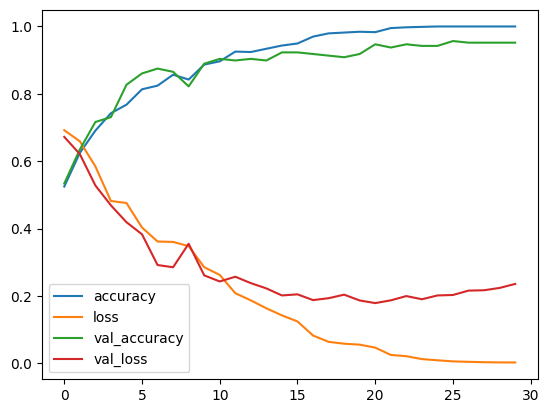

In [30]:
# barye fahmidan pishraftesh toie epoc haye mokhtalf ba estefad az liberiry panda
import pandas as pd
pd.DataFrame(history.history).plot()

In [31]:
model.save('CNN_Grain.keras')

In [32]:
model2= load_model('CNN_Grain.keras')

In [33]:
labels = ["Barli", "Rice"]

# to Analayise amalakrde system barsi konim

In [34]:
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)
actual_classes = np.argmax(y_test, axis=1)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step


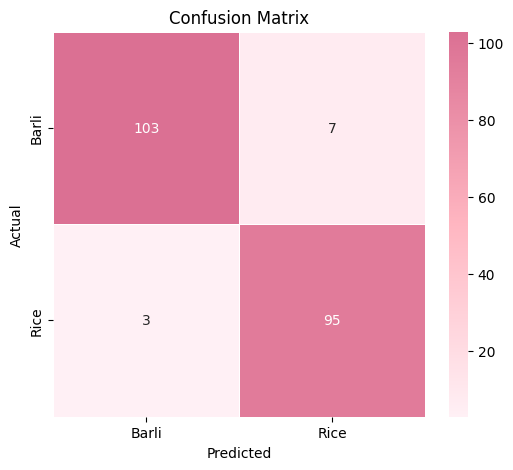

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

cm = confusion_matrix(actual_classes, predicted_classes)

# Custom pink gradient with more depth
baby_pink_cmap = LinearSegmentedColormap.from_list("baby_pink", ["#FFF0F5", "#FFB6C1", "#DB7093"])

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap=baby_pink_cmap,
            xticklabels=labels, yticklabels=labels,
            cbar=True, linewidths=0.5, linecolor="white")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

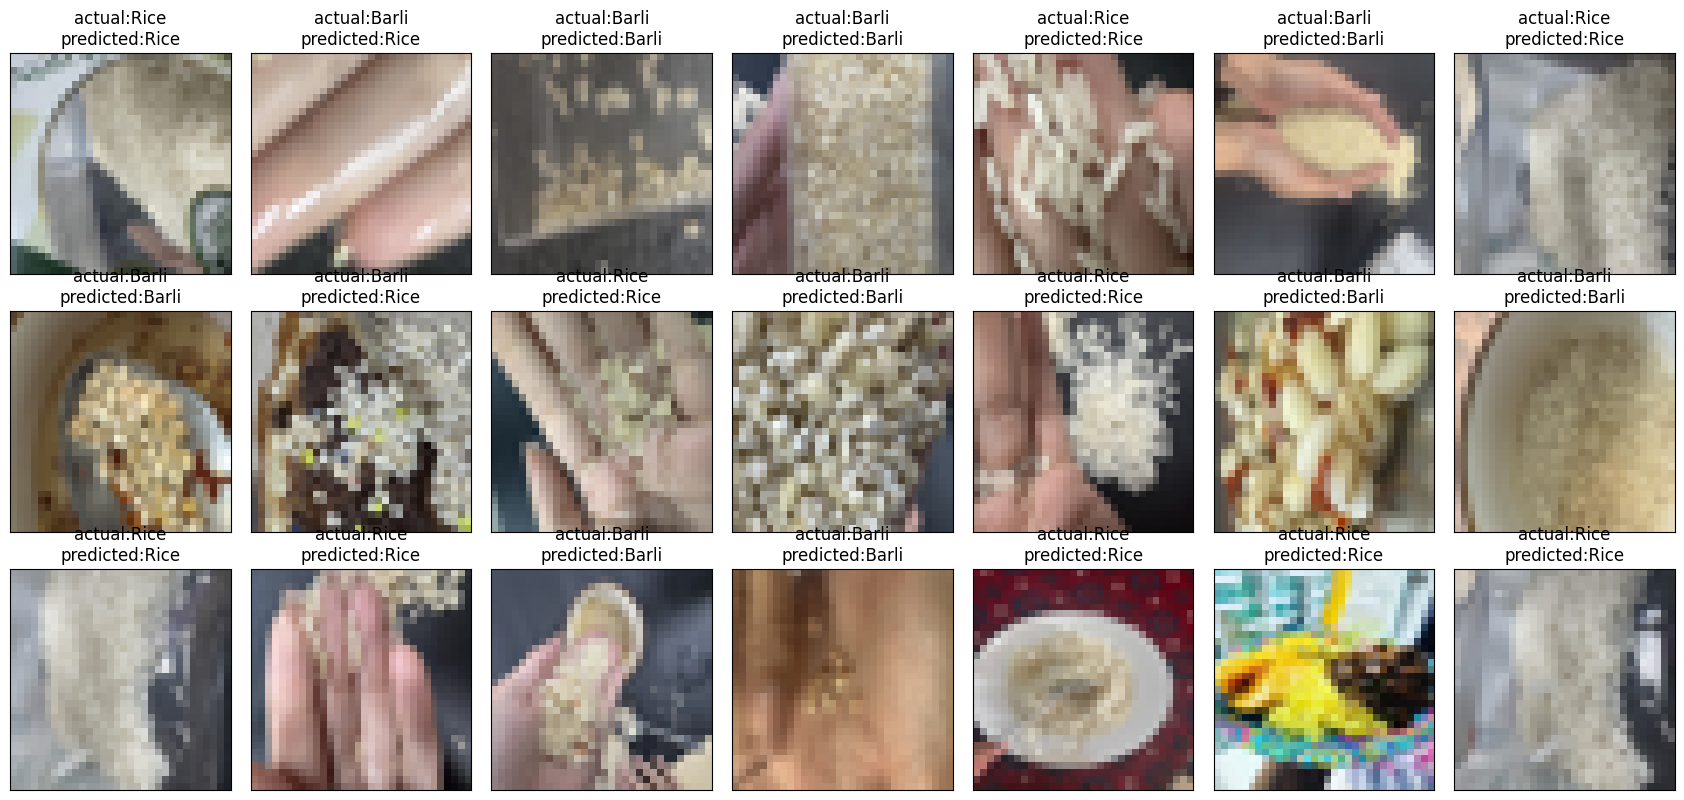

In [36]:
#tasviri amalkard bebinim
# Viewing predictions on sample images
fig, axes = plt.subplots(ncols=7, nrows=3, sharex=False,
    sharey=True, figsize=(17, 8))
index = 0
for i in range(3):
    for j in range(7):
        axes[i,j].set_title('actual:' + labels[actual_classes[index]] + '\n' + 'predicted:' + labels[predicted_classes[index]])
        axes[i,j].imshow(X_test[index])
        axes[i,j].get_xaxis().set_visible(False)
        axes[i,j].get_yaxis().set_visible(False)
        index += 1
plt.tight_layout()
plt.show()

In [37]:
model_handle_map = {
  "efficientnetv2-s": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet1k_s/feature_vector/2",
  "efficientnetv2-m": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet1k_m/feature_vector/2",
  "efficientnetv2-l": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet1k_l/feature_vector/2",
  "efficientnetv2-s-21k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_s/feature_vector/2",
  "efficientnetv2-m-21k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_m/feature_vector/2",
  "efficientnetv2-l-21k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_l/feature_vector/2",
  "efficientnetv2-xl-21k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_xl/feature_vector/2",
  "efficientnetv2-b0-21k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b0/feature_vector/2",
  "efficientnetv2-b1-21k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b1/feature_vector/2",
  "efficientnetv2-b2-21k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b2/feature_vector/2",
  "efficientnetv2-b3-21k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b3/feature_vector/2",
  "efficientnetv2-s-21k-ft1k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_s/feature_vector/2",
  "efficientnetv2-m-21k-ft1k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_m/feature_vector/2",
  "efficientnetv2-l-21k-ft1k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_l/feature_vector/2",
  "efficientnetv2-xl-21k-ft1k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_xl/feature_vector/2",
  "efficientnetv2-b0-21k-ft1k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_b0/feature_vector/2",
  "efficientnetv2-b1-21k-ft1k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_b1/feature_vector/2",
  "efficientnetv2-b2-21k-ft1k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_b2/feature_vector/2",
  "efficientnetv2-b3-21k-ft1k": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_b3/feature_vector/2",
  "efficientnetv2-b0": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet1k_b0/feature_vector/2",
  "efficientnetv2-b1": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet1k_b1/feature_vector/2",
  "efficientnetv2-b2": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet1k_b2/feature_vector/2",
  "efficientnetv2-b3": "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet1k_b3/feature_vector/2",
  "efficientnet_b0": "https://tfhub.dev/tensorflow/efficientnet/b0/feature-vector/1",
  "efficientnet_b1": "https://tfhub.dev/tensorflow/efficientnet/b1/feature-vector/1",
  "efficientnet_b2": "https://tfhub.dev/tensorflow/efficientnet/b2/feature-vector/1",
  "efficientnet_b3": "https://tfhub.dev/tensorflow/efficientnet/b3/feature-vector/1",
  "efficientnet_b4": "https://tfhub.dev/tensorflow/efficientnet/b4/feature-vector/1",
  "efficientnet_b5": "https://tfhub.dev/tensorflow/efficientnet/b5/feature-vector/1",
  "efficientnet_b6": "https://tfhub.dev/tensorflow/efficientnet/b6/feature-vector/1",
  "efficientnet_b7": "https://tfhub.dev/tensorflow/efficientnet/b7/feature-vector/1",
  "bit_s-r50x1": "https://tfhub.dev/google/bit/s-r50x1/1",
  "inception_v3": "https://tfhub.dev/google/imagenet/inception_v3/feature-vector/4",
  "inception_resnet_v2": "https://tfhub.dev/google/imagenet/inception_resnet_v2/feature-vector/4",
  "resnet_v1_50": "https://tfhub.dev/google/imagenet/resnet_v1_50/feature-vector/4",
  "resnet_v1_101": "https://tfhub.dev/google/imagenet/resnet_v1_101/feature-vector/4",
  "resnet_v1_152": "https://tfhub.dev/google/imagenet/resnet_v1_152/feature-vector/4",
  "resnet_v2_50": "https://tfhub.dev/google/imagenet/resnet_v2_50/feature-vector/4",
  "resnet_v2_101": "https://tfhub.dev/google/imagenet/resnet_v2_101/feature-vector/4",
  "resnet_v2_152": "https://tfhub.dev/google/imagenet/resnet_v2_152/feature-vector/4",
  "nasnet_large": "https://tfhub.dev/google/imagenet/nasnet_large/feature_vector/4",
  "nasnet_mobile": "https://tfhub.dev/google/imagenet/nasnet_mobile/feature_vector/4",
  "pnasnet_large": "https://tfhub.dev/google/imagenet/pnasnet_large/feature_vector/4",
  "mobilenet_v2_100_224": "https://tfhub.dev/google/imagenet/mobilenet_v2_100_224/feature_vector/4",
  "mobilenet_v2_130_224": "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/feature_vector/4",
  "mobilenet_v2_140_224": "https://tfhub.dev/google/imagenet/mobilenet_v2_140_224/feature_vector/4",
  "mobilenet_v3_small_100_224": "https://tfhub.dev/google/imagenet/mobilenet_v3_small_100_224/feature_vector/5",
  "mobilenet_v3_small_075_224": "https://tfhub.dev/google/imagenet/mobilenet_v3_small_075_224/feature_vector/5",
  "mobilenet_v3_large_100_224": "https://tfhub.dev/google/imagenet/mobilenet_v3_large_100_224/feature_vector/5",
  "mobilenet_v3_large_075_224": "https://tfhub.dev/google/imagenet/mobilenet_v3_large_075_224/feature_vector/5",
}

model_image_size_map = {
  "efficientnetv2-s": 384,
  "efficientnetv2-m": 480,
  "efficientnetv2-l": 480,
  "efficientnetv2-b0": 224,
  "efficientnetv2-b1": 240,
  "efficientnetv2-b2": 260,
  "efficientnetv2-b3": 300,
  "efficientnetv2-s-21k": 384,
  "efficientnetv2-m-21k": 480,
  "efficientnetv2-l-21k": 480,
  "efficientnetv2-xl-21k": 512,
  "efficientnetv2-b0-21k": 224,
  "efficientnetv2-b1-21k": 240,
  "efficientnetv2-b2-21k": 260,
  "efficientnetv2-b3-21k": 300,
  "efficientnetv2-s-21k-ft1k": 384,
  "efficientnetv2-m-21k-ft1k": 480,
  "efficientnetv2-l-21k-ft1k": 480,
  "efficientnetv2-xl-21k-ft1k": 512,
  "efficientnetv2-b0-21k-ft1k": 224,
  "efficientnetv2-b1-21k-ft1k": 240,
  "efficientnetv2-b2-21k-ft1k": 260,
  "efficientnetv2-b3-21k-ft1k": 300,
  "efficientnet_b0": 224,
  "efficientnet_b1": 240,
  "efficientnet_b2": 260,
  "efficientnet_b3": 300,
  "efficientnet_b4": 380,
  "efficientnet_b5": 456,
  "efficientnet_b6": 528,
  "efficientnet_b7": 600,
  "inception_v3": 299,
  "inception_resnet_v2": 299,
  "nasnet_large": 331,
  "pnasnet_large": 331,
}


import itertools
import os

import matplotlib.pylab as plt
import numpy as np

import tensorflow as tf
import tensorflow_hub as hub

print("TF version:", tf.__version__)
print("Hub version:", hub.__version__)
print("GPU is", "available" if tf.config.list_physical_devices('GPU') else "NOT AVAILABLE")


TF version: 2.20.0
Hub version: 0.16.1
GPU is NOT AVAILABLE


In [38]:
#importing the libraries you'll need for pretrained models.
import itertools
import os

import matplotlib.pylab as plt
import numpy as np

import tensorflow as tf
import tensorflow_hub as hub

print("TF version:", tf.__version__)
print("Hub version:", hub.__version__)
print("GPU is", "available" if tf.config.list_physical_devices('GPU') else "NOT AVAILABLE")


TF version: 2.20.0
Hub version: 0.16.1
GPU is NOT AVAILABLE


In [39]:
model_name = "efficientnetv2-m-21k"
model_handle = model_handle_map.get(model_name)
pixels = model_image_size_map.get(model_name, 224)

print(f"Selected model: {model_name} : {model_handle}")
IMAGE_SIZE = (pixels, pixels)
print(f"Input size {IMAGE_SIZE}")

BATCH_SIZE = 16

Selected model: efficientnetv2-m-21k : https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_m/feature_vector/2
Input size (480, 480)


In [40]:
def build_dataset(subset):
  return tf.keras.preprocessing.image_dataset_from_directory(
      data_dir,
      validation_split=.20,
      subset=subset,
      label_mode="categorical",
      # Seed needs to provided when using validation_split and shuffle = True.
      # A fixed seed is used so that the validation set is stable across runs.
      seed=123,
      image_size=IMAGE_SIZE,
      batch_size=1)

train_ds = build_dataset("training")
class_names = tuple(train_ds.class_names)
train_size = train_ds.cardinality().numpy()
train_ds = train_ds.unbatch().batch(BATCH_SIZE)
train_ds = train_ds.repeat()

normalization_layer = tf.keras.layers.Rescaling(1. / 255)
preprocessing_model = tf.keras.Sequential([normalization_layer])
do_data_augmentation = False
if do_data_augmentation:
  preprocessing_model.add(
      tf.keras.layers.RandomRotation(40))
  preprocessing_model.add(
      tf.keras.layers.RandomTranslation(0, 0.2))
  preprocessing_model.add(
      tf.keras.layers.RandomTranslation(0.2, 0))
  # Like the old tf.keras.preprocessing.image.ImageDataGenerator(),
  # image sizes are fixed when reading, and then a random zoom is applied.
  # If all training inputs are larger than image_size, one could also use
  # RandomCrop with a batch size of 1 and rebatch later.
  preprocessing_model.add(
      tf.keras.layers.RandomZoom(0.2, 0.2))
  preprocessing_model.add(
      tf.keras.layers.RandomFlip(mode="horizontal"))
train_ds = train_ds.map(lambda images, labels:
                        (preprocessing_model(images), labels))

val_ds = build_dataset("validation")
valid_size = val_ds.cardinality().numpy()
val_ds = val_ds.unbatch().batch(BATCH_SIZE)
val_ds = val_ds.map(lambda images, labels:
                    (normalization_layer(images), labels))

Found 897 files belonging to 2 classes.
Using 718 files for training.
Found 897 files belonging to 2 classes.
Using 179 files for validation.


In [41]:
!pip install tf_keras -q
import tf_keras

do_fine_tuning = False
model = tf_keras.Sequential([
    tf_keras.layers.InputLayer(input_shape=IMAGE_SIZE + (3,)),
    hub.KerasLayer(model_handle, trainable=do_fine_tuning),
    tf_keras.layers.Dropout(rate=0.2),
    tf_keras.layers.Dense(len(class_names),
                           kernel_regularizer=tf_keras.regularizers.l2(0.0001))
])
model.build((None,) + IMAGE_SIZE + (3,))
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1280)              53150388  
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 2)                 2562      
                                                                 
Total params: 53152950 (202.76 MB)
Trainable params: 2562 (10.01 KB)
Non-trainable params: 53150388 (202.75 MB)
_________________________________________________________________


In [42]:
model.compile(
  optimizer=tf_keras.optimizers.SGD(learning_rate=0.005, momentum=0.9),
  loss=tf_keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=0.1),
  metrics=['accuracy'])

In [43]:
steps_per_epoch = train_size // BATCH_SIZE
validation_steps = valid_size // BATCH_SIZE
hist = model.fit(
    train_ds,
    epochs=5, steps_per_epoch=steps_per_epoch,
    validation_data=val_ds,
    validation_steps=validation_steps).history

Epoch 1/5
44/44 [==============================] - 1773s 38s/step - loss: 0.5370 - accuracy: 0.9347 - val_loss: 0.3233 - val_accuracy: 0.9489
Epoch 2/5
44/44 [==============================] - 1625s 37s/step - loss: 0.4448 - accuracy: 0.9402 - val_loss: 0.2873 - val_accuracy: 0.9830
Epoch 3/5
44/44 [==============================] - 1672s 38s/step - loss: 0.3255 - accuracy: 0.9672 - val_loss: 0.2707 - val_accuracy: 0.9886
Epoch 4/5
44/44 [==============================] - 1556s 36s/step - loss: 0.2867 - accuracy: 0.9772 - val_loss: 0.2378 - val_accuracy: 0.9943
Epoch 5/5
44/44 [==============================] - 1577s 36s/step - loss: 0.2774 - accuracy: 0.9843 - val_loss: 0.2416 - val_accuracy: 1.0000


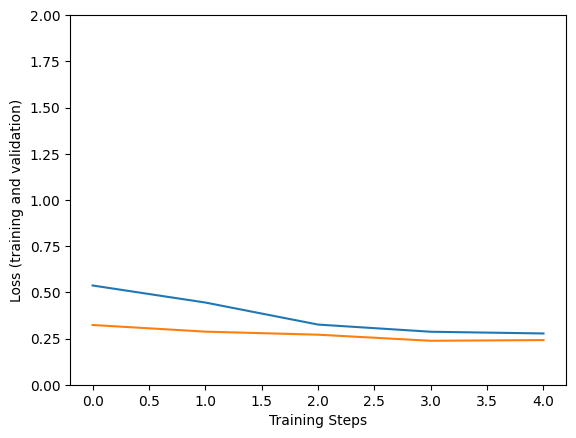

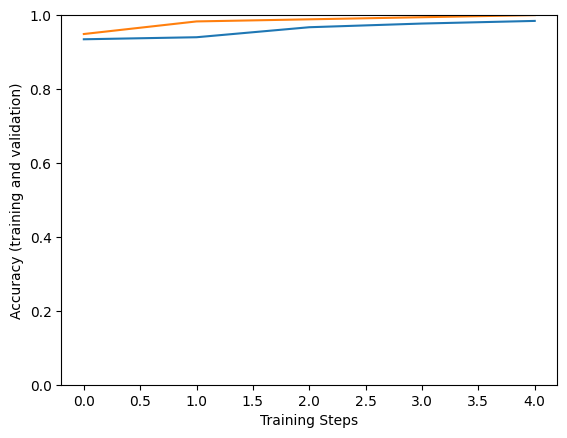

In [44]:
plt.figure()
plt.ylabel("Loss (training and validation)")
plt.xlabel("Training Steps")
plt.ylim([0,2])
plt.plot(hist["loss"])
plt.plot(hist["val_loss"])

plt.figure()
plt.ylabel("Accuracy (training and validation)")
plt.xlabel("Training Steps")
plt.ylim([0,1])
plt.plot(hist["accuracy"])
plt.plot(hist["val_accuracy"])

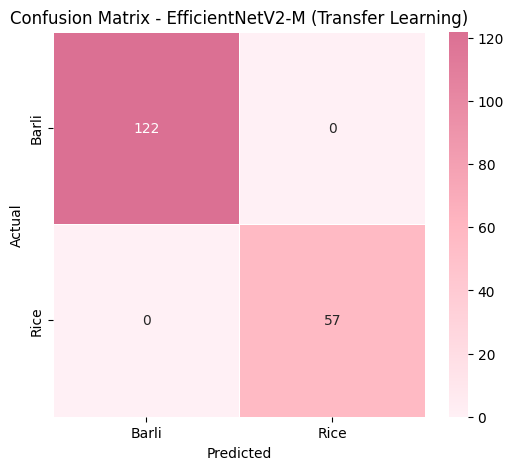

In [45]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Get true labels and predictions from val_ds
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)

baby_pink_cmap = LinearSegmentedColormap.from_list("baby_pink", ["#FFF0F5", "#FFB6C1", "#DB7093"])

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap=baby_pink_cmap,
            xticklabels=class_names, yticklabels=class_names,
            cbar=True, linewidths=0.5, linecolor="white")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - EfficientNetV2-M (Transfer Learning)")
plt.show()

In [51]:
model.compile(
    optimizer=tf_keras.optimizers.SGD(learning_rate=0.005, momentum=0.9),
    loss=tf_keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=0.1),
    metrics=['accuracy']
)

hist = model.fit(
    train_ds,
    epochs=10,
    steps_per_epoch=train_size // BATCH_SIZE,
    validation_data=val_ds,
    validation_steps=valid_size // BATCH_SIZE
)

Epoch 1/10
44/44 [==============================] - 1569s 35s/step - loss: 0.3081 - accuracy: 0.9801 - val_loss: 0.3174 - val_accuracy: 0.9943
Epoch 2/10
44/44 [==============================] - 1598s 37s/step - loss: 0.2549 - accuracy: 0.9886 - val_loss: 0.2419 - val_accuracy: 1.0000
Epoch 3/10
44/44 [==============================] - 1582s 36s/step - loss: 0.2580 - accuracy: 0.9929 - val_loss: 0.2376 - val_accuracy: 1.0000
Epoch 4/10
44/44 [==============================] - 1679s 38s/step - loss: 0.2522 - accuracy: 0.9915 - val_loss: 0.2227 - val_accuracy: 1.0000
Epoch 5/10
44/44 [==============================] - 1607s 37s/step - loss: 0.2288 - accuracy: 0.9986 - val_loss: 0.2200 - val_accuracy: 1.0000
Epoch 6/10
44/44 [==============================] - 1566s 36s/step - loss: 0.2268 - accuracy: 1.0000 - val_loss: 0.2222 - val_accuracy: 1.0000
Epoch 7/10
44/44 [==============================] - 1626s 37s/step - loss: 0.2282 - accuracy: 0.9986 - val_loss: 0.2238 - val_accuracy: 1.0000

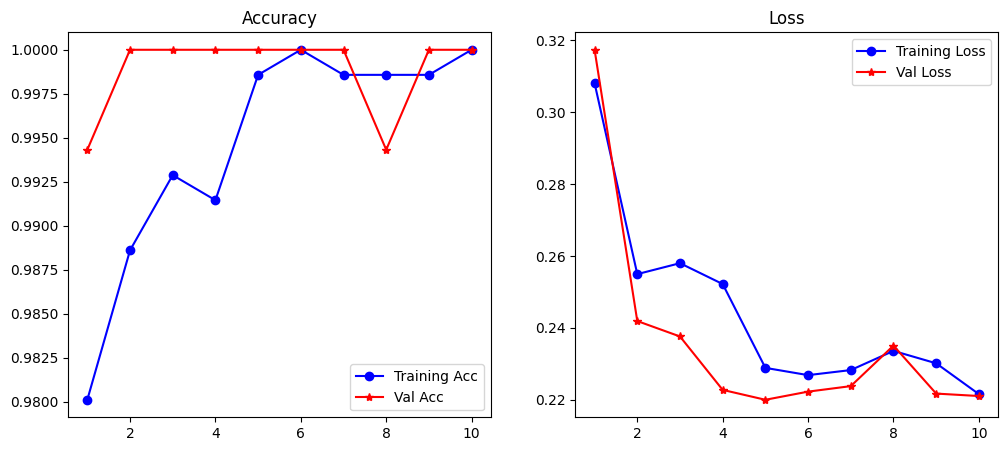

In [52]:
import matplotlib.pyplot as plt

acc = hist.history['accuracy']
val_acc = hist.history['val_accuracy']
loss = hist.history['loss']
val_loss = hist.history['val_loss']
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo-', label='Training Acc')
plt.plot(epochs, val_acc, 'r*-', label='Val Acc')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'bo-', label='Training Loss')
plt.plot(epochs, val_loss, 'r*-', label='Val Loss')
plt.title('Loss')
plt.legend()

plt.show()

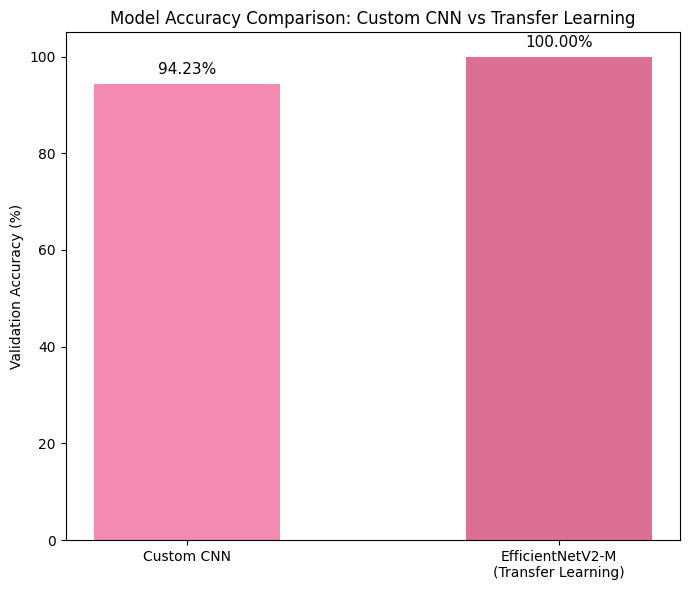

In [53]:
import matplotlib.pyplot as plt

model_names = ["Custom CNN", "EfficientNetV2-M\n(Transfer Learning)"]
accuracies = [94.23, 100.00]

fig, ax = plt.subplots(figsize=(7, 6))
bars = ax.bar(model_names, accuracies, color=["#F28AB2", "#DB7093"], width=0.5)
ax.set_ylabel("Validation Accuracy (%)")
ax.set_ylim(0, 105)
ax.set_title("Model Accuracy Comparison: Custom CNN vs Transfer Learning")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}%', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

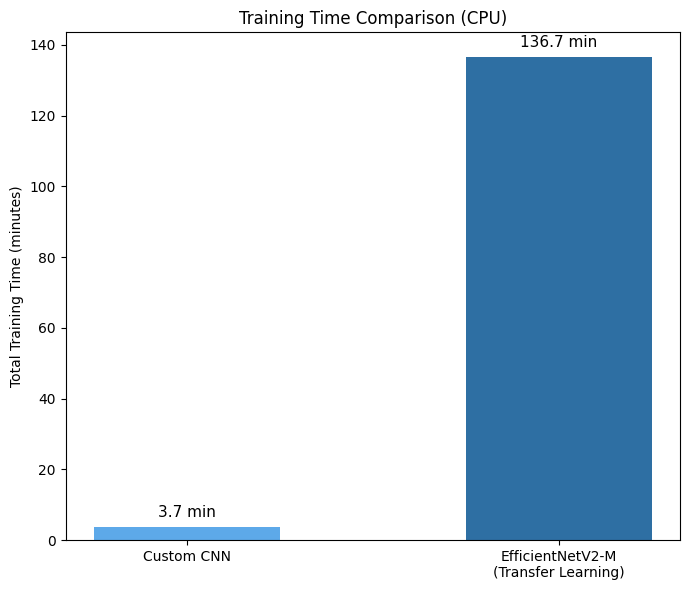

In [54]:
import matplotlib.pyplot as plt

model_names = ["Custom CNN", "EfficientNetV2-M\n(Transfer Learning)"]
training_minutes = [3.7, 136.7]

fig, ax = plt.subplots(figsize=(7, 6))
bars = ax.bar(model_names, training_minutes, color=["#5DA9E9", "#2E6FA3"], width=0.5)
ax.set_ylabel("Total Training Time (minutes)")
ax.set_title("Training Time Comparison (CPU)")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f} min', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()